# 04 · Cloud teacher: TI-STGNN (run on Kaggle GPU)

The teacher sees **all stations at once** and knows where the wind blows. It is built from 5 blocks:

```
all stations x 24 h x (23 sensor features + 7 ERA5 weather)
  1. Embedding                       turn each hour's numbers into a vector
  2. Transformer over time           each station looks at its own last 24 h        -> feat_seq, attention
  3. Wind graph attention (GAT)      each station listens to its UPWIND neighbours   -> h_spatial
  4. ADR physics                     advection + diffusion + reaction between stations -> h_adr
  5. Decoder + future weather        PM2.5 / PM10 change for +1 ... +6 h
```

**Ablation:** we switch blocks off to see what each one adds.

| variant | graph (3) | wind (3) | ADR (4) | question |
|---|---|---|---|---|
| T0 | – | – | – | how good is "time only"? |
| T1 | ✓ | – | – | do neighbours help? |
| T2 | ✓ | ✓ | – | does knowing the wind help? |
| T3 | ✓ | ✓ | ✓ | does transport physics help? |

**Fair comparison:** the teacher's station inputs are the same simulated sensor features as the student's.
Its advantage is the network (neighbours, wind, physics), never cleaner PM.

Papers: TransNet (Dimri et al. 2026) for the wind graph and ADR, WSDST-GAT (Wu et al. 2026) for GAT + Transformer
+ decoder, Wang et al. 2024 for future weather in the decoder.

## 0. Setup

In [1]:
# imports
import math
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from torch import nn
from torch.nn import functional as F

In [2]:
# where the data is (Kaggle or laptop) and where results go
ON_KAGGLE = Path("/kaggle/input").exists()
if ON_KAGGLE:
    FEAT = next(Path("/kaggle/input").rglob("grid_u0.npz")).parent
    OUT = Path("/kaggle/working")
else:
    FEAT = Path("../data/4_features")
    OUT = Path("../data/5_models/teacher")
OUT.mkdir(parents=True, exist_ok=True)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("data:", FEAT, "| device:", DEVICE)

data: ..\data\4_features | device: cpu


In [3]:
# settings (SMOKE = tiny quick run to test the notebook; the real run is on Kaggle)
SMOKE = not ON_KAGGLE
VARIANTS = ["T0", "T1", "T2", "T3"]
SETTINGS = dict(
    d_model=64, heads=4, layers=2, dropout=0.1,            # size of the model
    d_min_km=1.0, calm_ms=0.3, sigma_km=10.0,              # graph
    adr_steps=2, adr_h=0.1,                                 # physics block
    batch=16, lr=1e-3, weight_decay=1e-4,                   # training
    samples_per_epoch=20_000, max_epochs=40, patience=6,
    station_dropout=0.1, pinball_weight=0.5, folds=3, seed=0,
)
if SMOKE:
    SETTINGS.update(samples_per_epoch=64, max_epochs=1, folds=2)
H = 6                                                       # the teacher forecasts 6 hours ahead
torch.manual_seed(SETTINGS["seed"])
SETTINGS

{'d_model': 64,
 'heads': 4,
 'layers': 2,
 'dropout': 0.1,
 'd_min_km': 1.0,
 'calm_ms': 0.3,
 'sigma_km': 10.0,
 'adr_steps': 2,
 'adr_h': 0.1,
 'batch': 16,
 'lr': 0.001,
 'weight_decay': 0.0001,
 'samples_per_epoch': 64,
 'max_epochs': 1,
 'patience': 6,
 'station_dropout': 0.1,
 'pinball_weight': 0.5,
 'folds': 2,
 'seed': 0}

## 1. Data
`grid_u<k>.npz` (from 03): `X[hour, station, 23 features]`, masks `M`, ERA5 weather `W[hour, station, 7]`,
true PM `pm[hour, station, 2]` (targets only), and station info. One grid per virtual unit (3 "versions" of the network).

In [4]:
# load the 3 grids
grids = {u: dict(np.load(FEAT / f"grid_u{u}.npz")) for u in range(3)}
g0 = grids[0]
stations = list(g0["stations"])
print("hours:", g0["X"].shape[0], "| stations:", len(stations), "| features:", g0["X"].shape[2])

hours: 76680 | stations: 32 | features: 23


In [5]:
# training stations (27) and all stations (32 = + 5 never-seen stations for the final test)
train_idx = np.flatnonzero(~g0["holdout"])
all_idx = np.arange(len(stations))
lat, lon = g0["static"][:, 0], g0["static"][:, 1]
len(train_idx), len(all_idx)

(27, 32)

In [6]:
# mean / std of the 30 inputs (23 sensor + 7 weather), from training hours and stations only
train_hours = np.flatnonzero(g0["split"] == "train")
x_train = np.concatenate([g0["X"][train_hours][:, train_idx], g0["W"][train_hours][:, train_idx]], axis=2).reshape(-1, 30)
m_train = np.concatenate([g0["M"][train_hours][:, train_idx], np.ones_like(g0["W"][train_hours][:, train_idx], np.uint8)], axis=2).reshape(-1, 30)
x_train = np.where(m_train > 0, x_train, np.nan)
MEAN, STD = np.nanmean(x_train, axis=0), np.maximum(np.nanstd(x_train, axis=0), 1e-3)
STATIC = (g0["static"] - g0["static"].mean(0)) / np.maximum(g0["static"].std(0), 1e-3)
del x_train, m_train

## 2. One graph sample = all stations at one hour $t$
| input | shape | what |
|---|---|---|
| X, M | [N, 24, 30] | last 24 h: 23 sensor features + 7 ERA5 weather (z-scored), and masks |
| S | [N, 6] | lat, lon, elevation, ... (z-scored) |
| X_fut | [N, 6, 9] | ERA5 weather at t+1 … t+6 + hour of day (sin, cos) |
| wind_t | [N, 2] | wind speed, direction FROM (deg) now |
| y, y_mask | [N, 12] | targets $\ln(1+PM_{t+h}) - \ln(1+PM_t)$, h = 1…6, PM2.5 then PM10 |

Note: the "future weather" is ERA5 actual weather (old weather forecasts are not archived) → a limitation we report.

In [7]:
# cut one sample out of a grid: stations `idx` at hour t
def make_sample(g, t, idx):
    past, future = np.arange(t - 23, t + 1), np.arange(t + 1, t + H + 1)
    assert g["ts"][past].max() == g["ts"][t] < g["ts"][future].min()          # never any future in the inputs
    x = np.concatenate([g["X"][past][:, idx], g["W"][past][:, idx]], axis=2).transpose(1, 0, 2)
    m = np.concatenate([g["M"][past][:, idx], np.isfinite(g["W"][past][:, idx])], axis=2).transpose(1, 0, 2)
    m = m * np.isfinite(x)
    x = np.where(m > 0, (x - MEAN) / STD, 0.0)

    hour = 2 * np.pi * g["ist_hour"][future] / 24
    clock = np.broadcast_to(np.stack([np.sin(hour), np.cos(hour)], 1), (len(idx), H, 2))
    weather_future = (g["W"][future][:, idx].transpose(1, 0, 2) - MEAN[23:]) / STD[23:]
    x_fut = np.nan_to_num(np.concatenate([weather_future, clock], axis=2))

    u, v = np.nan_to_num(g["W"][t, idx, 3]), np.nan_to_num(g["W"][t, idx, 4])
    wind_t = np.stack([np.hypot(u, v), np.rad2deg(np.arctan2(-u, -v)) % 360], axis=1)

    log_pm_now, log_pm_future = np.log1p(g["pm"][t, idx]), np.log1p(g["pm"][future][:, idx])
    y = (log_pm_future - log_pm_now).transpose(1, 2, 0).reshape(len(idx), 2 * H)
    return dict(X=x, M=m, S=STATIC[idx], X_fut=x_fut, wind_t=wind_t, y=np.nan_to_num(y), y_mask=np.isfinite(y))

In [8]:
# look at the shapes of one sample
sample = make_sample(g0, int(train_hours[5000]), train_idx)
{k: v.shape for k, v in sample.items()}

{'X': (27, 24, 30),
 'M': (27, 24, 30),
 'S': (27, 6),
 'X_fut': (27, 6, 9),
 'wind_t': (27, 2),
 'y': (27, 12),
 'y_mask': (27, 12)}

In [9]:
# stack samples into a batch of torch tensors; optionally hide random stations (makes the model robust)
def make_batch(pairs, idx, drop=0.0, rng=None):
    samples = [make_sample(grids[u], t, idx) for u, t in pairs]
    batch = {k: np.stack([s[k] for s in samples]).astype(np.float32) for k in samples[0]}
    if drop > 0:
        keep = (rng.random(batch["M"].shape[:2]) >= drop)[:, :, None, None]
        batch["X"], batch["M"] = batch["X"] * keep, batch["M"] * keep
    return {k: torch.tensor(v, device=DEVICE) for k, v in batch.items()}

In [10]:
# all (unit, hour) pairs of a split where the window fits and at least one station has a target
def sample_pairs(split, idx):
    pairs = []
    for u, g in grids.items():
        T = len(g["ts"])
        t = np.arange(23, T - H)
        same_split = (g["split"][t] == split) & (g["split"][t + H] == split)
        log_pm = np.log1p(g["pm"][:, idx])
        has_target = np.zeros(T, bool)
        for h in range(1, H + 1):
            has_target[: T - h] |= np.isfinite(log_pm[h:] - log_pm[:-h]).any(axis=(1, 2))
        pairs += [(u, int(x)) for x in t[same_split & has_target[t]]]
    return pairs


train_pairs, val_pairs = sample_pairs("train", train_idx), sample_pairs("val", train_idx)
len(train_pairs), len(val_pairs)

(157665, 26334)

## 3. The graph

**Distance and bearing** between stations (great circle):
$d_{ij}$ in km, $\theta_{ij}$ = compass direction from station $i$ to station $j$.

**Wind prior** (TransNet): how strongly the wind at station $i$ carries air to station $j$
$$w_{ij} = \frac{\mathrm{ReLU}\big(ws_i\cos(\theta_{ij} - \varphi_i)\big)}{\max(d_{ij},\ 1\,km)},\qquad \varphi_i = wd_i^{from} + 180°$$
- $\varphi_i$ = direction the air moves **to** (TransNet puts the "from" direction there, which points upwind — we fix that).
- Calm air (< 0.3 m/s) carries nothing. For T1 (no wind) we use $w_{ij} = 1/d_{ij}$.

In [11]:
# distance (km) and bearing (deg) between every pair of stations
def geometry(lat, lon):
    la, lo = np.deg2rad(lat)[:, None], np.deg2rad(lon)[:, None]
    a = np.sin((la.T - la) / 2) ** 2 + np.cos(la) * np.cos(la.T) * np.sin((lo.T - lo) / 2) ** 2
    dist = 2 * 6371 * np.arcsin(np.sqrt(np.clip(a, 0, 1)))
    y = np.sin(lo.T - lo) * np.cos(la.T)
    x = np.cos(la) * np.sin(la.T) - np.sin(la) * np.cos(la.T) * np.cos(lo.T - lo)
    bearing = np.rad2deg(np.arctan2(y, x)) % 360
    return torch.tensor(dist, dtype=torch.float32, device=DEVICE), torch.tensor(bearing, dtype=torch.float32, device=DEVICE)

In [12]:
# wind prior w[b, i, j]: air from station i to station j (formula above)
def wind_prior(ws, wd_from, dist, bearing):
    toward = (wd_from + 180) % 360
    angle = torch.deg2rad(bearing[None] - toward[:, :, None])
    w = torch.relu(ws[:, :, None] * torch.cos(angle)) / dist.clamp_min(SETTINGS["d_min_km"])[None]
    w = w * (ws >= SETTINGS["calm_ms"]).float()[:, :, None]
    return w * (1 - torch.eye(dist.shape[0], device=DEVICE))


# T1: no wind, closer stations simply matter more
def distance_prior(dist):
    return (1 / dist.clamp_min(SETTINGS["d_min_km"])) * (1 - torch.eye(dist.shape[0], device=DEVICE))

In [13]:
# check: wind from the west -> the eastern neighbour gets weight, the western one nothing
d, b = geometry(np.array([28.6, 28.6, 28.6]), np.array([76.9, 77.0, 77.1]))    # west, middle, east
w = wind_prior(torch.full((1, 3), 3.0, device=DEVICE), torch.full((1, 3), 270.0, device=DEVICE), d, b)[0]
print(f"middle -> east: {w[1, 2]:.3f}   middle -> west: {w[1, 0]:.3f}")
assert w[1, 2] > 0 and w[1, 0] == 0

middle -> east: 0.307   middle -> west: 0.000


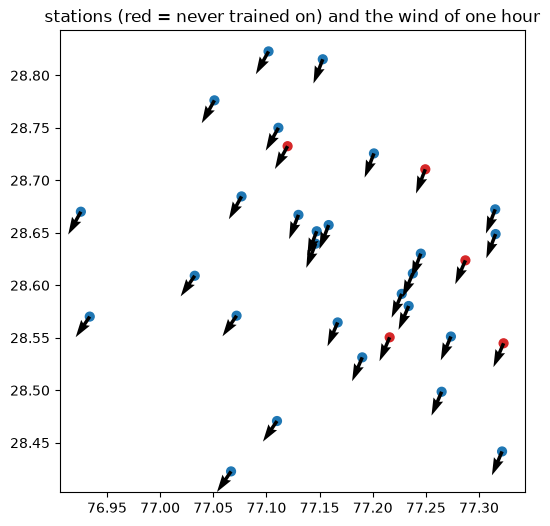

In [14]:
# draw the stations and the wind arrows of one hour
dist, bearing = geometry(lat[train_idx], lon[train_idx])
t = int(train_hours[3000])
plt.figure(figsize=(6, 6))
plt.scatter(lon, lat, c=np.where(g0["holdout"], "tab:red", "tab:blue"), s=40)
plt.quiver(lon, lat, g0["W"][t, :, 3], g0["W"][t, :, 4])
plt.title("stations (red = never trained on) and the wind of one hour")
plt.show()

## 4. Model blocks

### 4.1 Embedding
Every hour of every station: $e = W_v[\,x \odot m,\ m\,] + W_s\,s$ — the mask tells the model "0 because missing" apart from a real 0.

In [15]:
# embedding: values + masks + static info -> vector of size D
class Embedding(nn.Module):
    def __init__(self, d):
        super().__init__()
        self.values = nn.Linear(2 * 30, d)
        self.static = nn.Linear(6, d)

    def forward(self, x, m, s):                       # x, m: [B, N, 24, 30], s: [B, N, 6]
        return self.values(torch.cat([x * m, m], dim=-1)) + self.static(s)[:, :, None, :]

### 4.2 Transformer over time (each station on its own)
Standard pre-norm Transformer layer: $x \leftarrow x + \text{Attention}(\text{LN}(x))$, $x \leftarrow x + \text{FFN}(\text{LN}(x))$,
with sine/cosine position codes. We keep the **attention map** — the student copies it later (Na et al.: $L_{AFD}$).

In [16]:
# one Transformer layer that also returns its attention map
class TimeLayer(nn.Module):
    def __init__(self, d, heads, dropout):
        super().__init__()
        self.norm1, self.norm2 = nn.LayerNorm(d), nn.LayerNorm(d)
        self.attn = nn.MultiheadAttention(d, heads, dropout=dropout, batch_first=True)
        self.ffn = nn.Sequential(nn.Linear(d, 4 * d), nn.GELU(), nn.Dropout(dropout), nn.Linear(4 * d, d))

    def forward(self, x):
        h = self.norm1(x)
        a, attention = self.attn(h, h, h, need_weights=True, average_attn_weights=False)
        x = x + a
        x = x + self.ffn(self.norm2(x))
        return x, attention

In [17]:
# position codes: hour 0 ... 23 as sines and cosines
def position_codes(length, d):
    pos = torch.arange(length, dtype=torch.float32)[:, None]
    freq = torch.exp(torch.arange(0, d, 2, dtype=torch.float32) * (-math.log(10000.0) / d))
    pe = torch.zeros(length, d)
    pe[:, 0::2], pe[:, 1::2] = torch.sin(pos * freq), torch.cos(pos * freq)
    return pe

### 4.3 Wind graph attention (GAT)
Station $i$ (receiver) mixes in information from stations $j$ (senders):
$$\text{score}_{ij} = \text{LeakyReLU}(a_r^\top W h_i + a_s^\top W h_j) + \beta \log(w_{j \to i} + 10^{-3})$$
$$\alpha_{ij} = \text{softmax}_j(\text{score}_{ij}),\qquad h_i^{spatial} = h_i + W_o \sum_j \alpha_{ij} W h_j$$
Careful: the prior is the edge **from** sender $j$ **to** receiver $i$, i.e. $w_{j\to i}$ (the transpose of $w$).
Missing stations send nothing. $\alpha$ is learned; the wind only nudges it.

In [18]:
# wind-biased graph attention
class WindGAT(nn.Module):
    def __init__(self, d):
        super().__init__()
        self.W = nn.Linear(d, d, bias=False)
        self.a_receiver, self.a_sender = nn.Linear(d, 1, bias=False), nn.Linear(d, 1, bias=False)
        self.out = nn.Linear(d, d)
        self.beta = nn.Parameter(torch.tensor(1.0))

    def forward(self, h, prior, valid):               # h: [B, N, D], prior: [B, N, N], valid: [B, N]
        n = h.shape[1]
        eye = torch.eye(n, dtype=torch.bool, device=h.device)[None]
        wh = self.W(h)
        score = F.leaky_relu(self.a_receiver(wh) + self.a_sender(wh).transpose(1, 2), 0.2)   # [B, receiver, sender]
        incoming = prior.transpose(1, 2)                                                     # w[j -> i]
        incoming = torch.where(eye, incoming.amax(-1, keepdim=True).expand_as(incoming), incoming)   # self-loop
        score = score + self.beta * torch.log(incoming + 1e-3)
        allowed = valid[:, None, :].bool() | eye
        alpha = torch.softmax(score.masked_fill(~allowed, float("-inf")), dim=-1)
        return h + self.out(alpha @ wh), score

### 4.4 ADR physics (TransNet): K small steps of size $h$
**Advection** (wind carries pollution). $P_{ij}$ = share of station $j$'s state that moves to $i$: softmax of the
GAT scores over the **receivers**, so every station sends out exactly 100 % — mass is conserved:
$$U_i \leftarrow U_i + h\Big(\sum_j P_{ij} U_j - U_i\sum_k P_{ki}\Big)$$
**Diffusion** (pollution spreads to close stations), on the graph $A_{ij} = e^{-d_{ij}^2/\sigma^2}$ with Laplacian
$\hat L = I - D^{-1/2}AD^{-1/2} = V\Lambda V^\top$, solved exactly per channel $c$ with $\kappa_c \in [0, 1]$:
$$U \leftarrow V\,\text{diag}\Big(\frac{1}{1 + h\,\kappa_c\,\lambda}\Big)V^\top U$$
**Reaction** (local change: emissions, chemistry, weather):
$$U \leftarrow U + h\cdot \text{ReLU}\big(R_1 U + \tanh(R_2 U)\odot U + R_3\,\bar h_{time} + R_4\,\text{weather}\big)$$

In [19]:
# advection weights: softmax over receivers -> every station sends exactly 100 %
def advection_weights(score, valid):
    n = score.shape[-1]
    v = valid.bool()
    allowed = v[:, :, None] & v[:, None, :] & ~torch.eye(n, dtype=torch.bool, device=score.device)[None]
    return torch.nan_to_num(torch.softmax(score.masked_fill(~allowed, float("-inf")), dim=1))

In [20]:
# diffusion basis: eigen-decomposition of the distance graph's Laplacian (missing stations are cut out)
def diffusion_basis(dist, valid):
    n = dist.shape[0]
    A = torch.exp(-dist**2 / SETTINGS["sigma_km"] ** 2) * (1 - torch.eye(n, device=dist.device))
    A = A[None] * valid[:, :, None] * valid[:, None, :]
    degree = A.sum(-1)
    d_inv_sqrt = torch.where(degree > 0, degree.clamp_min(1e-12).rsqrt(), torch.zeros_like(degree))
    L = torch.diag_embed((degree > 0).float()) - d_inv_sqrt[:, :, None] * A * d_inv_sqrt[:, None, :]
    lam, V = torch.linalg.eigh(L)
    return V, lam.clamp(0, 2)

In [21]:
# the ADR block
class ADR(nn.Module):
    def __init__(self, d):
        super().__init__()
        self.kappa_raw = nn.Parameter(torch.full((d,), 0.5))
        self.R1 = nn.Sequential(nn.Linear(d, d), nn.LayerNorm(d))
        self.R2, self.R3, self.R4 = nn.Linear(d, d), nn.Linear(d, d), nn.Linear(7, d)

    def forward(self, U, score, V, lam, time_summary, weather, valid):
        P = advection_weights(score, valid)
        kappa = F.hardtanh(self.kappa_raw, 0, 1)                       # no negative diffusion
        h = SETTINGS["adr_h"]
        for _ in range(SETTINGS["adr_steps"]):
            U = U + h * (P @ U - P.sum(1)[:, :, None] * U)              # advection
            U = V @ ((1 / (1 + h * kappa * lam[:, :, None])) * (V.transpose(1, 2) @ U))   # diffusion
            U = U + h * F.relu(self.R1(U) + torch.tanh(self.R2(U)) * U + self.R3(time_summary) + self.R4(weather))  # reaction
        return U

In [22]:
# check: advection conserves mass
P = advection_weights(torch.randn(2, 5, 5), torch.ones(2, 5))
U = torch.randn(2, 5, 3)
U_next = U + 0.1 * (P @ U - P.sum(1)[:, :, None] * U)
assert torch.allclose(U_next.sum(1), U.sum(1), atol=1e-5)
print("advection keeps the total the same")

advection keeps the total the same


### 4.5 Decoder
Fuse the spatial/physics state with the station's own time state: $z = \text{GLU}([h_{adr}, h_t])$.
One query per forecast hour $k$: $q_k = \text{pos}_k + W_f\,\text{weather}_{t+k} + z$.
One Transformer decoder layer (self-attention over the 6 hours, cross-attention to the station's 24 h), then
heads for the forecast and for a q10-q90 band (lower = forecast − softplus(a), upper = forecast + softplus(b)).

In [23]:
# decoder: 6 forecast hours with future weather
class Decoder(nn.Module):
    def __init__(self, d, heads, dropout):
        super().__init__()
        self.fuse = nn.Linear(2 * d, 2 * d)
        self.hour_code = nn.Embedding(H, d)
        self.weather = nn.Linear(9, d)
        self.layer = nn.TransformerDecoderLayer(d, heads, 4 * d, dropout, batch_first=True, norm_first=True)
        self.forecast = nn.Linear(d, 2)                 # PM2.5, PM10
        self.band = nn.Linear(d, 4)                     # distances to q10 / q90

    def forward(self, h_adr, h_t, feat_seq, x_fut):
        B, N, L, D = feat_seq.shape
        z = F.glu(self.fuse(torch.cat([h_adr, h_t], dim=-1)), dim=-1)
        q = self.hour_code.weight[None, None] + self.weather(x_fut) + z[:, :, None]       # [B, N, 6, D]
        out = self.layer(q.reshape(B * N, H, D), feat_seq.reshape(B * N, L, D)).reshape(B, N, H, D)
        y = self.forecast(out)                                                             # [B, N, 6, 2]
        spread = F.softplus(self.band(out))
        to_12 = lambda t: t.permute(0, 1, 3, 2).reshape(B, N, 2 * H)   # [pm25 h1..h6, pm10 h1..h6]
        return to_12(y), to_12(y - spread[..., :2]), to_12(y + spread[..., 2:])

### 4.6 The whole teacher

In [24]:
# TI-STGNN: blocks 1-5 wired together; use_graph / use_wind / use_adr switch blocks on and off
class Teacher(nn.Module):
    def __init__(self, use_graph, use_wind, use_adr):
        super().__init__()
        d = SETTINGS["d_model"]
        self.use_wind = use_wind
        self.embed = Embedding(d)
        self.register_buffer("pos", position_codes(24, d), persistent=False)
        self.time_layers = nn.ModuleList([TimeLayer(d, SETTINGS["heads"], SETTINGS["dropout"]) for _ in range(SETTINGS["layers"])])
        self.norm = nn.LayerNorm(d)
        self.gat = WindGAT(d) if use_graph else None
        self.adr = ADR(d) if use_adr else None
        self.decoder = Decoder(d, SETTINGS["heads"], SETTINGS["dropout"])

    def forward(self, b, dist, bearing):
        B, N, L, _ = b["X"].shape
        valid = (b["M"][..., :23].sum(dim=(2, 3)) > 0).float()           # station has any sensor data

        # 1-2: each station's own 24 hours
        z = (self.embed(b["X"], b["M"], b["S"]) + self.pos).reshape(B * N, L, -1)
        for layer in self.time_layers:
            z, attention = layer(z)
        feat_seq = self.norm(z).reshape(B, N, L, -1)
        attention = attention.reshape(B, N, -1, L, L)
        h_t = feat_seq[:, :, -1]                                          # state at the current hour

        # 3: listen to the neighbours
        h_spatial, score = h_t, None
        if self.gat is not None:
            ws, wd = b["wind_t"][..., 0], b["wind_t"][..., 1]
            prior = wind_prior(ws, wd, dist, bearing) if self.use_wind else distance_prior(dist)[None].expand(B, -1, -1)
            h_spatial, score = self.gat(h_t, prior, valid)

        # 4: transport physics
        h_adr = h_spatial
        if self.adr is not None:
            with torch.no_grad():
                V, lam = diffusion_basis(dist, valid)
            h_adr = self.adr(h_spatial, score, V, lam, feat_seq.mean(2), b["X"][:, :, -1, 23:], valid)

        # 5: forecast
        y, q10, q90 = self.decoder(h_adr, h_t, feat_seq, b["X_fut"])
        return dict(y=y, q10=q10, q90=q90, feat_seq=feat_seq, attention=attention, h_spatial=h_spatial, h_adr=h_adr)

In [25]:
# the 4 variants
VARIANT_SWITCHES = {"T0": (False, False, False), "T1": (True, False, False),
                    "T2": (True, True, False), "T3": (True, True, True)}

In [26]:
# check: all variants run and give 12 outputs per station
batch = make_batch(train_pairs[:2], train_idx)
for name, switches in VARIANT_SWITCHES.items():
    out = Teacher(*switches).to(DEVICE)(batch, dist, bearing)
    print(name, "y", tuple(out["y"].shape), "| parameters:", sum(p.numel() for p in Teacher(*switches).parameters()))

T0 y (2, 27, 12) | parameters: 189126
T1 y (2, 27, 12) | parameters: 197511
T2 y (2, 27, 12) | parameters: 197511
T3 y (2, 27, 12) | parameters: 210695


## 5. Training
**Loss** = Huber error of the forecast + pinball loss for the q10 / q90 band (only where the true PM exists):
$$\text{pinball}_\tau(y, q) = \max(\tau(y-q),\ (\tau-1)(y-q))$$
Plain loop: AdamW, learning rate halves when validation stops improving, early stopping, best model kept.

In [27]:
# loss: Huber on the forecast + 0.5 x pinball on the band, ignoring missing targets
def loss_fn(out, b):
    mask = b["y_mask"]
    n = mask.sum().clamp_min(1)
    loss = (F.huber_loss(out["y"], b["y"], reduction="none") * mask).sum() / n
    for q, tau in ((out["q10"], 0.1), (out["q90"], 0.9)):
        diff = b["y"] - q
        loss = loss + SETTINGS["pinball_weight"] * (torch.maximum(tau * diff, (tau - 1) * diff) * mask).sum() / n
    return loss

In [28]:
# RMSE per output (ln change) on a list of samples
@torch.no_grad()
def evaluate(model, pairs, idx, batch_size=32):
    model.eval()
    dist_eval, bearing_eval = geometry(lat[idx], lon[idx])
    se, count = torch.zeros(12, device=DEVICE), torch.zeros(12, device=DEVICE)
    for k in range(0, len(pairs), batch_size):
        b = make_batch(pairs[k:k + batch_size], idx)
        out = model(b, dist_eval, bearing_eval)
        se += (((out["y"] - b["y"]) ** 2) * b["y_mask"]).sum((0, 1))
        count += b["y_mask"].sum((0, 1))
    names = [f"{p}_h{h}" for p in ("pm25", "pm10") for h in range(1, 7)]
    return pd.Series((se / count.clamp_min(1)).sqrt().cpu().numpy(), index=names)

In [29]:
# train one teacher (each epoch uses a fresh random sample of training hours)
def train_teacher(variant, train_list, folder):
    folder.mkdir(parents=True, exist_ok=True)
    rng = np.random.default_rng(SETTINGS["seed"])
    model = Teacher(*VARIANT_SWITCHES[variant]).to(DEVICE)
    opt = torch.optim.AdamW(model.parameters(), lr=SETTINGS["lr"], weight_decay=SETTINGS["weight_decay"])
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(opt, patience=2, factor=0.5)
    val_list = val_pairs[: (64 if SMOKE else 4000)]
    best, best_epoch, history = float("inf"), 0, []
    for epoch in range(SETTINGS["max_epochs"]):
        model.train()
        start = time.time()
        chosen = rng.choice(len(train_list), size=min(SETTINGS["samples_per_epoch"], len(train_list)), replace=False)
        for k in range(0, len(chosen), SETTINGS["batch"]):
            b = make_batch([train_list[i] for i in chosen[k:k + SETTINGS["batch"]]], train_idx, SETTINGS["station_dropout"], rng)
            loss = loss_fn(model(b, dist, bearing), b)
            opt.zero_grad()
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            opt.step()
        val_rmse = evaluate(model, val_list, train_idx).mean()
        scheduler.step(val_rmse)
        history.append(dict(epoch=epoch, val_rmse=val_rmse, seconds=round(time.time() - start)))
        print(history[-1])
        if val_rmse < best:
            best, best_epoch = val_rmse, epoch
            torch.save(model.state_dict(), folder / "best.pt")
        if epoch - best_epoch >= SETTINGS["patience"]:
            break
    model.load_state_dict(torch.load(folder / "best.pt", map_location=DEVICE))
    return model, pd.DataFrame(history)

## 6. Train T0 - T3 and compare
Persistence ("PM stays the same", $y = 0$) is the simple baseline every model must beat.

In [30]:
# train the 4 final teachers
test_pairs = sample_pairs("test", train_idx)
test_unseen = sample_pairs("test", all_idx)
if SMOKE:
    test_pairs, test_unseen = test_pairs[:64], test_unseen[:64]
teachers, results = {}, {}
for variant in VARIANTS:
    teachers[variant], history = train_teacher(variant, train_pairs, OUT / variant / "final")
    results[variant] = evaluate(teachers[variant], test_pairs, train_idx)
    history.to_csv(OUT / variant / "history.csv", index=False)

{'epoch': 0, 'val_rmse': np.float32(0.45191574), 'seconds': 1}


{'epoch': 0, 'val_rmse': np.float32(0.47423294), 'seconds': 1}


{'epoch': 0, 'val_rmse': np.float32(0.4717221), 'seconds': 1}


{'epoch': 0, 'val_rmse': np.float32(0.48993644), 'seconds': 1}


In [31]:
# persistence baseline on the same test samples (RMSE of y itself)
def persistence(pairs, idx):
    se, n = np.zeros(12), np.zeros(12)
    for u, t in pairs:
        s = make_sample(grids[u], t, idx)
        se += (s["y"] ** 2 * s["y_mask"]).sum(0)
        n += s["y_mask"].sum(0)
    return pd.Series(np.sqrt(se / np.maximum(n, 1)), index=results[VARIANTS[0]].index)

In [32]:
# results table: test RMSE of the ln change (lower = better)
table = pd.DataFrame({"persistence": persistence(test_pairs, train_idx), **results})
table.to_csv(OUT / "teacher_results.csv")
table.round(3)

,persistence,T0,T1,T2,T3
pm25_h1,0.152,0.466,0.371,0.495,0.333
pm25_h2,0.231,0.317,0.259,0.508,0.311
pm25_h3,0.284,0.412,0.321,0.667,0.329
pm25_h4,0.319,0.415,0.308,0.703,0.401
pm25_h5,0.342,0.440,0.334,0.652,0.460
pm25_h6,0.357,0.505,0.408,0.613,0.448
pm10_h1,0.133,0.475,0.472,0.276,0.873
pm10_h2,0.207,0.454,0.869,0.287,0.462
pm10_h3,0.255,0.296,0.592,0.315,0.733
pm10_h4,0.288,0.439,0.449,0.496,0.617


In [33]:
# the same, at the 5 stations the teacher never saw in training
pd.DataFrame({"persistence": persistence(test_unseen, all_idx),
              **{v: evaluate(m, test_unseen, all_idx) for v, m in teachers.items()}}).round(3)

,persistence,T0,T1,T2,T3
pm25_h1,0.147,0.464,0.375,0.502,0.327
pm25_h2,0.225,0.312,0.258,0.515,0.304
pm25_h3,0.278,0.406,0.312,0.673,0.322
pm25_h4,0.313,0.409,0.304,0.713,0.393
pm25_h5,0.336,0.433,0.328,0.660,0.458
pm25_h6,0.351,0.498,0.399,0.621,0.440
pm10_h1,0.132,0.478,0.466,0.273,0.869
pm10_h2,0.206,0.459,0.861,0.287,0.463
pm10_h3,0.255,0.296,0.583,0.313,0.731
pm10_h4,0.289,0.442,0.444,0.490,0.615


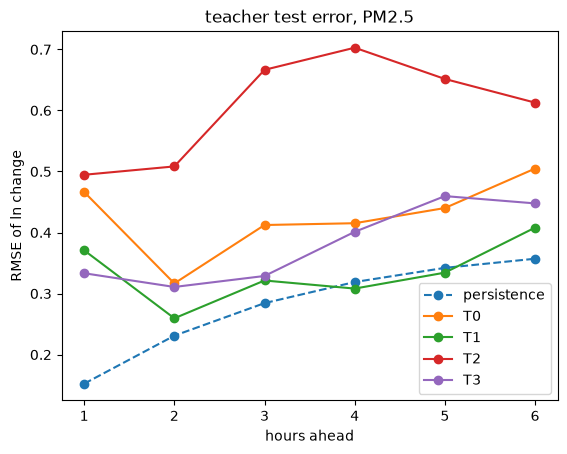

In [34]:
# plot: PM2.5 error by forecast hour
for name in table.columns:
    plt.plot(range(1, 7), table[name][:6], marker="o", label=name, ls="--" if name == "persistence" else "-")
plt.xlabel("hours ahead")
plt.ylabel("RMSE of ln change")
plt.title("teacher test error, PM2.5")
plt.legend()
plt.show()

## 7. Teacher outputs for the student (out-of-fold)
The student must never learn from a teacher that already saw the answer. So:
- the training hours are cut into `folds` blocks; for each block we train a teacher **without** it
  (plus a 30-hour gap on both sides) and let that teacher predict the block;
- validation windows are predicted by the final teacher (trained on all training hours).

For every distillation window (`kd_windows.parquet`) we save:

| output | shape | used for |
|---|---|---|
| forecast, h1-h3 | [6] | S1+: copy the forecast |
| time features, averaged per 2-hour patch | [12, 64] | S2+: $L_{feat}$ |
| attention importance per patch | [12] | S2+: $L_{AFD}$ weights |
| GAT state | [64] | S3+: $L_{spatial}$ |
| ADR state | [64] | S4: $L_{physics}$ |

In [35]:
# attention [heads, 24, 24] -> how important each 2-hour patch is (sums to 1), Na et al.
def patch_importance(attention):
    looked_at = attention.mean(0).sum(0)                       # how much all hours look at each hour
    w = np.exp((looked_at - looked_at.mean()) / (looked_at.std() + 1e-6))
    return (w / w.sum()).reshape(12, 2).sum(1)

In [36]:
# run a teacher on the hours of some windows and keep its outputs for those (station, hour) pairs
@torch.no_grad()
def teacher_outputs(model, windows, batch_size=16):
    model.eval()
    result = {k: [] for k in ("window_id", "y_teacher", "feat12", "afd12", "h_spatial", "h_adr")}
    groups = list(windows.groupby(["unit", "row"]))
    for k in range(0, len(groups), batch_size):
        chunk = groups[k:k + batch_size]
        out = model(make_batch([key for key, _ in chunk], train_idx), dist, bearing)
        for i, (_, w) in enumerate(chunk):
            pos = torch.as_tensor(np.searchsorted(train_idx, w.station.to_numpy()), device=DEVICE)
            result["window_id"].append(w.window_id.to_numpy())
            result["y_teacher"].append(out["y"][i, pos][:, [0, 1, 2, 6, 7, 8]].cpu().numpy())
            fs = out["feat_seq"][i, pos].cpu().numpy()
            result["feat12"].append(fs.reshape(len(w), 12, 2, -1).mean(2).astype(np.float16))
            result["afd12"].append(np.stack([patch_importance(a) for a in out["attention"][i, pos].cpu().numpy()]))
            result["h_spatial"].append(out["h_spatial"][i, pos].cpu().numpy().astype(np.float16))
            result["h_adr"].append(out["h_adr"][i, pos].cpu().numpy().astype(np.float16))
    return {k: np.concatenate(v) for k, v in result.items()}

In [37]:
# the distillation windows (from 03): station, unit, row (= hour), split
kd = pd.read_parquet(FEAT / "kd_windows.parquet")
if SMOKE:
    kd = kd.groupby("split").sample(200, random_state=0)
kd.split.value_counts()

split
train    200
val      200
Name: count, dtype: int64

In [38]:
# out-of-fold outputs for every variant
train_hours_all = np.array(sorted({t for _, t in train_pairs}))
for variant in VARIANTS:
    parts = []
    for fold, block in enumerate(np.array_split(train_hours_all, SETTINGS["folds"])):
        lo, hi = block.min() - 30, block.max() + 30
        fold_train = [(u, t) for u, t in train_pairs if not lo <= t <= hi]
        fold_model, _ = train_teacher(variant, fold_train, OUT / variant / f"fold{fold}")
        windows = kd[(kd.split == "train") & kd.row.between(block.min(), block.max())]
        if len(windows):
            parts.append(teacher_outputs(fold_model, windows))
    parts.append(teacher_outputs(teachers[variant], kd[kd.split == "val"]))
    outputs = {k: np.concatenate([p[k] for p in parts]) for k in parts[0]}
    np.savez(OUT / f"teacher_{variant}.npz", **outputs)
    print(variant, "outputs for", len(outputs["window_id"]), "windows")

{'epoch': 0, 'val_rmse': np.float32(0.45487633), 'seconds': 1}


{'epoch': 0, 'val_rmse': np.float32(0.49161223), 'seconds': 1}


T0 outputs for 400 windows


{'epoch': 0, 'val_rmse': np.float32(0.40821695), 'seconds': 1}


{'epoch': 0, 'val_rmse': np.float32(0.48024657), 'seconds': 1}


T1 outputs for 400 windows


... (2 outputs left out)

T2 outputs for 400 windows


{'epoch': 0, 'val_rmse': np.float32(0.3966473), 'seconds': 1}


{'epoch': 0, 'val_rmse': np.float32(0.3747536), 'seconds': 1}


T3 outputs for 400 windows
